# Huấn luyện kết hợp CIC-IDS2017 và InSDN: M1 / M2 / M3

Dùng đúng `run_three_models` của CLI `train_all.py --combined`. M3 học một Stacking mới từ dữ liệu cả hai nguồn, không ghép hai model M1/M2 đã lưu. M1/M2 chạy cùng protocol để so sánh trên đúng các hàng test.

**Mặc định huấn luyện đa lớp theo nhóm chung** (`MULTICLASS=True`), với bảng ánh xạ có version tại [LABEL_TAXONOMY.md](../docs/LABEL_TAXONOMY.md). Chuyển False để dùng lại BENIGN/ATTACK. M3 mới học từ cả hai nguồn; không gộp các model cũ. Huấn luyện dùng mẫu có class cap, không phải toàn bộ mọi hàng CSV.

Mặc định DO_TRAIN=False: đọc artifact. Để train thật, chọn tham số và OUT mới, đổi DO_TRAIN=True, Restart Kernel rồi Run All. Huấn luyện chạy cả ba cấu hình và có thể mất vài phút.

M3: RF + XGBoost + LightGBM -> Logistic Regression.

Lượt đa lớp hiện tại dùng CSV TrafficLabelling của CIC và bộ InSDN đủ ba tệp, gồm OVS.

In [1]:
%matplotlib inline
from argparse import Namespace
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/train_all.py').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from three_models import run_three_models
from features import FEATURES
DO_TRAIN = False
MULTICLASS = True
SEED, FOLDS = 42, 3
CAP, TREES = (2000, 60) if MULTICLASS else (5000, 120)
TUNE, STACK_SEARCH = True, MULTICLASS
RUN_NAME = "reference-csv-20261112" if MULTICLASS else "three-models"
CIC_DATA = ROOT / ('data/cic-reference/GeneratedLabelledFlows/TrafficLabelling' if MULTICLASS else 'data/MachineLearningCVE')
INSDN_DATA = ROOT / ('data/insdn-reference/mohdadilz-insdn-dataset/InSDN_DatasetCSV' if MULTICLASS else 'data/InSDN(2020)')
OUT = ROOT / f'experiments/notebook-{RUN_NAME}-seed{SEED}'
RESULT = ROOT / (f'experiments/{RUN_NAME}/seed{SEED}' if MULTICLASS else f'experiments/completion-20261110/three-models-seed{SEED}')
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))
display(pd.Series({'training_enabled': DO_TRAIN, 'seed': SEED, 'multiclass_families': MULTICLASS, 'cap_per_target_class_per_source': CAP,
                   'trees': TREES, 'folds': FOLDS, 'baseline_tuning': TUNE, 'meta_search': STACK_SEARCH,
                   'new_output': str(OUT)}, name='configuration').to_frame())

,configuration
training_enabled,False
seed,42
multiclass_families,True
cap_per_target_class_per_source,2000
trees,60
folds,3
baseline_tuning,True
meta_search,True
new_output,D:\Downloads\network-stacking-ids-20261107\net...


## 1. Hai nguồn và hợp đồng feature

Pipeline đọc mỗi nguồn theo chunk, ánh xạ tên cột về 12 feature chung, ánh xạ nhãn nhóm theo nguồn trước sampling; nhãn lạ bị từ chối. MULTICLASS=False đổi mọi subtype hợp lệ thành ATTACK. Nhãn gốc được giữ trong RawLabel ở nhánh đa lớp. Loại missing toàn bộ feature, vector trùng/mâu thuẫn trong mẫu; khử trùng giữa hai nguồn trước split. IP, RawLabel, Label và source_dataset không phải feature.

In [2]:
display(pd.DataFrame([
    {'configuration': 'M1', 'training_sources': 'CIC', 'input': str(CIC_DATA)},
    {'configuration': 'M2', 'training_sources': 'InSDN', 'input': str(INSDN_DATA)},
    {'configuration': 'M3', 'training_sources': 'CIC + InSDN', 'input': 'Union hai development set sau cleanup/split'}]))
display(pd.DataFrame({'shared_features': FEATURES}))

,configuration,training_sources,input
0,M1,CIC,D:\Downloads\network-stacking-ids-20261107\net...
1,M2,InSDN,D:\Downloads\network-stacking-ids-20261107\net...
2,M3,CIC + InSDN,Union hai development set sau cleanup/split


,shared_features
0,Destination Port
1,Flow Duration
2,Total Fwd Packets
3,Total Backward Packets
4,Total Length of Fwd Packets
5,Total Length of Bwd Packets
6,FIN Flag Count
7,SYN Flag Count
8,RST Flag Count
9,PSH Flag Count


## 2. Huấn luyện bằng pipeline chung

Mỗi nguồn chia stratified random 60/20/20. M1 chỉ học CIC, M2 chỉ học InSDN, M3 nối hai train và hai validation. Baseline chọn bằng CV train; stack chọn bằng validation, refit train+validation rồi đánh giá test.

M3 chỉ fit một lần ở bước refit cuối, rồi đánh giá Test CIC, Test InSDN và test gộp. Metrics test gộp tính trên các hàng nối lại, không trung bình hai F1. STACK_SEARCH=True tìm C/weight meta bằng train OOF và validation; mặc định bật trong nhánh đa lớp để khớp lượt đã lưu.

In [3]:
if DO_TRAIN:
    if OUT.exists():
        raise ValueError('OUT đã tồn tại. Chọn OUT mới trước khi train.')
    args = Namespace(cic_data=str(CIC_DATA), insdn_data=str(INSDN_DATA), out=str(OUT),
                     combined=True, multiclass=MULTICLASS, max_per_class=CAP, trees=TREES, seed=SEED,
                     folds=FOLDS, tune=TUNE, stack_search=STACK_SEARCH)
    run_three_models(args)
    RESULT = OUT
else:
    display(Markdown(f'Đọc artifact `{RESULT.relative_to(ROOT)}`; không train lại.'))
protocol = read_json(RESULT / 'protocol.json')
completed = read_json(RESULT / 'completed.json')
assert ('label_taxonomy' in protocol) == MULTICLASS
assert completed['result_rows'] == 30
assert set(completed['configurations']) == {'M1', 'M2', 'M3'}
if MULTICLASS:
    assert protocol['m3_stack_variant'] == 'trees'

Đọc artifact `experiments\reference-csv-20261112\seed42`; không train lại.

## 3. Sampling, cleanup và split

Số đếm nhãn gốc là toàn CSV; train/test thuộc mẫu đã cleanup. Class cap thay đổi cả tỷ lệ test. Nhóm chỉ có một nguồn được giữ riêng; Heartbleed dưới 15 mẫu bị loại và ghi rõ. Không so trực tiếp F1 theo nhóm với F1 subtype cũ.

In [4]:
display(pd.DataFrame({source: data['raw_class_counts'] for source, data in protocol['sources'].items()}).fillna(0).astype(int))
cleanup = protocol['cleanup_and_splits']
display(pd.DataFrame({'before_global_cleanup': cleanup['rows_before'], 'after_global_cleanup': cleanup['rows_after']}))
display(pd.Series({key: cleanup[key] for key in ['conflicting_rows_removed', 'duplicate_rows_removed', 'duplicate_policy']}, name='global_cleanup').to_frame())
counts = [{'source': source, 'partition': part, **labels}
          for source, parts in cleanup['split_counts'].items() for part, labels in parts.items()]
display(pd.DataFrame(counts))
if MULTICLASS:
    display(pd.Series(protocol['label_taxonomy']).drop('labels').to_frame('taxonomy'))
    display(pd.read_csv(RESULT / 'label_mapping.csv'))
    display(pd.read_csv(RESULT / 'family_support.csv'))
    display(pd.DataFrame({s: m['excluded_classes_below_minimum'] for s, m in protocol['sources'].items()}).fillna(0))


,cicids2017,insdn
BENIGN,2273097,0
DDoS,128027,121942
PortScan,158930,0
Bot,1966,0
Infiltration,36,0
Web Attack � Brute Force,1507,0
Web Attack � XSS,652,0
Web Attack � Sql Injection,21,0
FTP-Patator,7938,0
SSH-Patator,5897,0


,before_global_cleanup,after_global_cleanup
cicids2017,11439,11439
insdn,7696,7693


,global_cleanup
conflicting_rows_removed,0
duplicate_rows_removed,3
duplicate_policy,Remove contradictory family labels; keep first...


,source,partition,DDOS,BENIGN,RECON,BOT,DOS,BRUTE_FORCE,WEB_ATTACK,INFILTRATION,U2R
0,cicids2017,train,1200,1188,1186,1162,940,765,400,22.0,NaN
1,cicids2017,validation,400,397,395,387,314,255,133,7.0,NaN
2,cicids2017,test,400,397,396,387,313,255,133,7.0,NaN
3,insdn,train,93,1193,1194,98,1112,814,100,NaN,11.0
4,insdn,validation,31,398,398,33,371,271,34,NaN,3.0
5,insdn,test,31,398,398,33,371,271,34,NaN,3.0


,taxonomy
version,cic-insdn-families-v1
normalization,"trim/collapse whitespace, casefold, en/em/repl..."
policy,Union of families; retain source-specific clas...
sha256,e906caaae1368329f39a7143c0d9dd528c773f58d92ada...


,source_dataset,raw_label,family,raw_rows
0,cicids2017,BENIGN,BENIGN,2273097
1,cicids2017,DDoS,DDOS,128027
2,cicids2017,PortScan,RECON,158930
3,cicids2017,Bot,BOT,1966
4,cicids2017,Infiltration,INFILTRATION,36
5,cicids2017,Web Attack � Brute Force,BRUTE_FORCE,1507
6,cicids2017,Web Attack � XSS,WEB_ATTACK,652
7,cicids2017,Web Attack � Sql Injection,WEB_ATTACK,21
8,cicids2017,FTP-Patator,BRUTE_FORCE,7938
9,cicids2017,SSH-Patator,BRUTE_FORCE,5897


,family,cicids2017,insdn
0,BENIGN,1982,1989
1,BOT,1936,164
2,BRUTE_FORCE,1275,1356
3,DDOS,2000,155
4,DOS,1567,1854
5,INFILTRATION,36,0
6,RECON,1977,1990
7,U2R,0,17
8,WEB_ATTACK,666,168


,cicids2017,insdn
HEARTBLEED,11,0.0


## 4. Xác minh M3 học dữ liệu gộp và dùng test chung

Đối chiếu số hàng M3 với tổng hai nguồn và hash test M1/M3, M2/M3. Hash chứng minh dùng cùng vector test, không chứng minh các phiên mạng độc lập hoặc feature-extractor parity.

In [5]:
models = {name: read_json(RESULT / name / 'protocol.json') for name in ['M1', 'M2', 'M3']}
for part in ['train', 'validation']:
    for label in models['M3']['split_class_counts']['train']:
        assert models['M3']['split_class_counts'][part][label] == sum(cleanup['split_counts'][source][part].get(label, 0) for source in ['cicids2017', 'insdn'])
assert models['M1']['split_feature_sha256']['cicids2017'] == models['M3']['split_feature_sha256']['cicids2017']
assert models['M2']['split_feature_sha256']['insdn'] == models['M3']['split_feature_sha256']['insdn']
display(pd.DataFrame([{'configuration': name, 'sources': ', '.join(p['data']['training_sources']),
                       'train_rows': sum(p['split_class_counts']['train'].values()),
                       'validation_rows': sum(p['split_class_counts']['validation'].values()),
                       'final_fit_rows': sum(p['split_class_counts']['train'].values())+sum(p['split_class_counts']['validation'].values()),
                       'selected_stack': p['selected_stack']} for name, p in models.items()]))
display(Markdown('Đã kiểm tra: **M3 = union hai nguồn; hai test nguồn được tái sử dụng chính xác.**'))
if MULTICLASS:
    selection = read_json(RESULT / 'M3/selection.json')
    display(pd.Series(selection['stack_' + models['M3']['selected_stack']], name='M3').to_frame())


,configuration,sources,train_rows,validation_rows,final_fit_rows,selected_stack
0,M1,cicids2017,6863,2288,9151,diverse_C0.1_balanced
1,M2,insdn,4615,1539,6154,trees_C1_unweighted
2,M3,"cicids2017, insdn",11478,3827,15305,trees_C1_unweighted


Đã kiểm tra: **M3 = union hai nguồn; hai test nguồn được tái sử dụng chính xác.**

,M3
base_models,"[rf, xgb, lgbm]"
meta_C,1.0
meta_class_weight,None
validation_macro_f1,0.939698


## 5. Baseline và Stacking trên cùng test

Một seed có 30 hàng metrics: M1 6 + M2 6 + M3 3 test × 6 thuật toán. Để có mean/SD, chạy đủ seed 7/21/42 với OUT riêng rồi dùng summarize.py; không chọn seed tốt nhất để báo cáo.

,configuration,test_dataset,algorithm,accuracy,macro_f1,benign_false_positive_rate,attack_false_negative_rate
0,M1,cicids2017,dt,0.967220,0.951979,0.045340,0.009519
1,M1,cicids2017,rf,0.971154,0.953147,0.035264,0.006346
2,M1,cicids2017,xgb,0.973339,0.965342,0.027708,0.005288
3,M1,cicids2017,lgbm,0.975087,0.951888,0.025189,0.005288
4,M1,cicids2017,lr,0.814685,0.784699,0.387909,0.001586
5,M1,cicids2017,stacking,0.972465,0.964690,0.035264,0.004231
6,M2,insdn,dt,0.966212,0.951078,0.017588,0.001753
7,M2,insdn,rf,0.970760,0.955293,0.000000,0.004382
8,M2,insdn,xgb,0.950617,0.935585,0.027638,0.004382
9,M2,insdn,lgbm,0.971410,0.948288,0.007538,0.004382


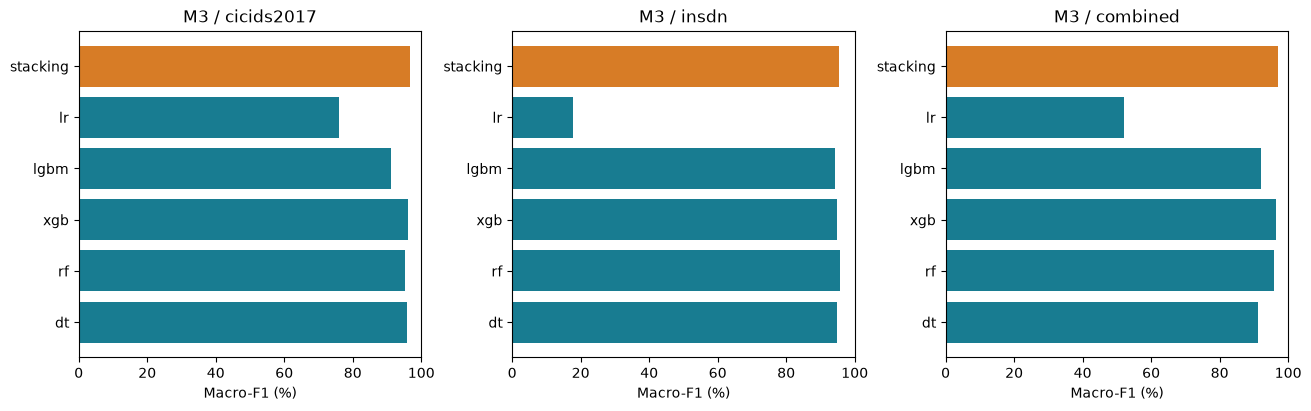

In [6]:
comparison = pd.read_csv(RESULT / 'comparison_all.csv')
assert len(comparison) == 30
assert not comparison.duplicated(['configuration', 'test_dataset', 'algorithm']).any()
display(comparison[['configuration', 'test_dataset', 'algorithm', 'accuracy', 'macro_f1', 'benign_false_positive_rate', 'attack_false_negative_rate']])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout='constrained')
for ax, source in zip(axes, ['cicids2017', 'insdn', 'combined']):
    scores = comparison.loc[comparison.configuration.eq('M3') & comparison.test_dataset.eq(source)].set_index('algorithm').macro_f1 * 100
    ax.barh(scores.index, scores, color=['#d77c26' if name == 'stacking' else '#187c91' for name in scores.index])
    ax.set(xlim=(0, 100), xlabel='Macro-F1 (%)', title=f'M3 / {source}')
plt.show()

## 6. Confusion matrix của M3 trên ba test

Hàng là nhãn thật, cột là dự đoán; lấy thứ tự nhãn từ CSV. Accuracy so với ground truth; smoke match so với dự đoán đã lưu để kiểm tra tái lập.

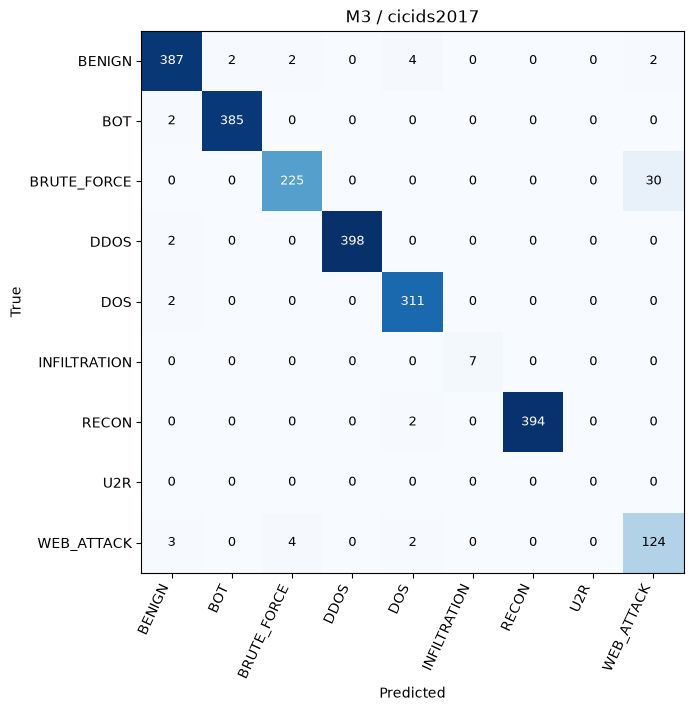

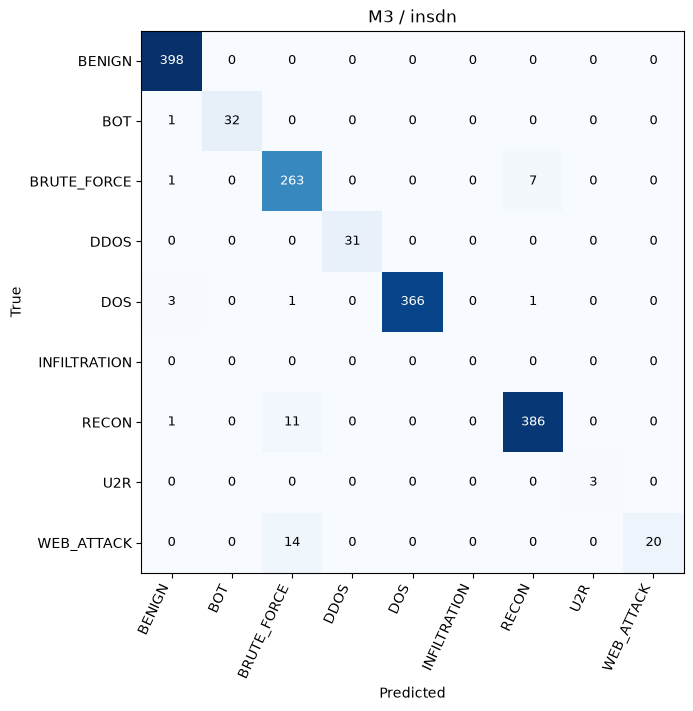

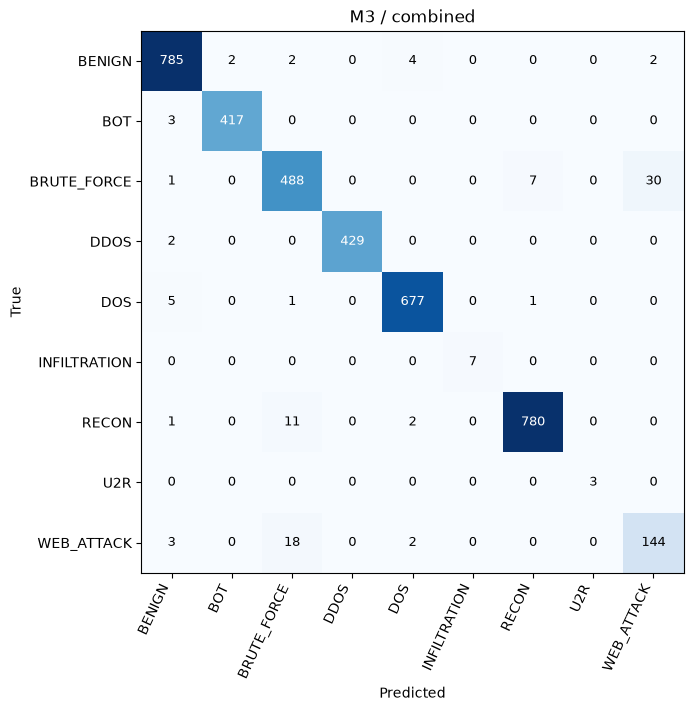

In [7]:
for source in ['cicids2017', 'insdn', 'combined']:
    matrix = pd.read_csv(RESULT / 'M3' / source / 'confusion_stacking.csv', index_col=0)
    fig, ax = plt.subplots(figsize=(9, 7), layout='constrained')
    ax.imshow(matrix, cmap='Blues')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=65, ha='right')
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Predicted', ylabel='True', title=f'M3 / {source}')
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            ax.text(j, i, str(matrix.iloc[i,j]), ha='center', va='center', fontsize=9,
                    color='white' if matrix.iloc[i,j] > matrix.to_numpy().max()/2 else 'black')
    plt.show()

## 7. Model đầu ra và kiểm chứng

Artifact gồm preprocessing, model, feature và nhãn. Chỉ load joblib tự tạo/đáng tin cậy. Cell sau chỉ in lệnh, không ghi thêm evaluation hoặc tự bắt gói tin.

In [8]:
display(pd.DataFrame([{'configuration': name, 'model': str(RESULT / name / 'models/stacking_ids.joblib'),
                       'exists': (RESULT / name / 'models/stacking_ids.joblib').is_file()} for name in ['M1', 'M2', 'M3']]))
relative = RESULT.relative_to(ROOT).as_posix()
print(fr'.\.venv\Scripts\python.exe src/check_model.py --model {relative}/M3/models/stacking_ids.joblib --csv {relative}/M3/cicids2017/smoke_test.csv')
print(fr'.\.venv\Scripts\python.exe src/evaluate_model.py --model {relative}/M3/models/stacking_ids.joblib --csv {relative}/splits/cicids2017/test.csv --out experiments/evaluate-combined-cic-new')

,configuration,model,exists
0,M1,D:\Downloads\network-stacking-ids-20261107\net...,True
1,M2,D:\Downloads\network-stacking-ids-20261107\net...,True
2,M3,D:\Downloads\network-stacking-ids-20261107\net...,True


.\.venv\Scripts\python.exe src/check_model.py --model experiments/reference-csv-20261112/seed42/M3/models/stacking_ids.joblib --csv experiments/reference-csv-20261112/seed42/M3/cicids2017/smoke_test.csv
.\.venv\Scripts\python.exe src/evaluate_model.py --model experiments/reference-csv-20261112/seed42/M3/models/stacking_ids.joblib --csv experiments/reference-csv-20261112/seed42/splits/cicids2017/test.csv --out experiments/evaluate-combined-cic-new


## Giới hạn

- Tên cột chung chưa chứng minh cùng cách đo feature; cần parity trước khi suy rộng sang lab.
- Class cap/cleanup thay đổi phân bố, random split chưa tách phiên/thời gian, M3 đã thấy hai miền trong train.
- M3 có nhiều hàng học hơn M1/M2. Xem size-ablation và experiment.ipynb để so sánh cùng cỡ mẫu.
- Tuning trước OOF chưa phải nested CV hoàn chỉnh; test chỉ báo cáo, ES không được bảo đảm thắng baseline.
- M3 đa lớp hiện có 9 nhóm; HEARTBLEED bị loại do 11 mẫu. InSDN đầy đủ có BOT và WEB_ATTACK; các lớp hiếm cần báo support, đặc biệt U2R chỉ có 17 flow gốc. Taxonomy là quy ước đề tài có nguồn đối chiếu, chưa được thẩm định độc lập.
- Xem THREE_MODELS.md, STACKING_SCOPE.md, CURRENT_RESULTS.md. Kết quả CSV offline chưa phải độ chính xác live.